# Reweighting closure tests

Reweight the reference **`S + EWSBI10`** using `r_SBI` and `r_qqZZ`, and compare it with directly simulated **SBI**, **qqZZ**, and **SBI + qqZZ** events. The event weight is `weight_kFact`.

For each reference event, the combined reweighted weight is

$$
w_{\mathrm{rw}}(x)=w_{\mathrm{ref}}(x)
\left[\frac{\lambda_{\mathrm{SBI}}}{\lambda_{\mathrm{ref}}}r_{\mathrm{SBI}}(x)
+\frac{\lambda_{qqZZ}}{\lambda_{\mathrm{ref}}}r_{qqZZ}(x)\right].
$$

Here $\lambda_j=\sum_{i\in j}w_i$ is the signed yield of the selected sample, **before plotting-range cuts**. The stored ratios are used directly: their normalization is part of the test.

| Variable | Range | Bin width |
|---|---|---|
| `NN_disc_New` | −1 to 1 | 0.05 |
| `m4l_fsr` | 150 to 2000 GeV | 50 GeV |

Each comparison has a **weighted-yield plot followed by a normalized-shape plot**, both with a **reweighted / direct** ratio panel. The combined target is shown first, followed by the two components. Figures are saved as PNG/PDF in Drive.

## Setup

Use a CPU runtime. This uses the same compatible package versions as notebook 01. If setup reports a stale import, choose **Runtime → Restart session**, then **Run all**. The plotting helper is downloaded again and PNG/PDF export is checked before loading the ntuple.

In [1]:
%pip -q install "matplotlib==3.10.0" "mplhep==0.4.1" tables


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 45.1 MB/s eta 0:00:00


In [2]:


# Installing a package cannot replace a copy already loaded in this session.
import sys
from importlib.metadata import version

for package in ("matplotlib", "mplhep", "numpy", "pandas", "tables"):
    loaded = sys.modules.get(package)
    if loaded is not None and loaded.__version__ != version(package):
        raise RuntimeError(
            f"{package} changed on disk while it was loaded. "
            "Choose Runtime > Restart session, then Run all."
        )

from pathlib import Path
from urllib.request import urlretrieve
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import mplhep as hep
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    import utils as offshell_utils
else:
    drive.mount("/content/drive")
    urlretrieve(
        "https://raw.githubusercontent.com/rafaellopesdesa/offshell_reweighting/main/utils.py",
        "/content/offshell_utils.py",
    )
    import offshell_utils

# Reload the downloaded helper even if this Colab runtime was used before.
importlib.invalidate_caches()
importlib.reload(offshell_utils)
load_columns = offshell_utils.load_columns
plot_reweighting_comparison = offshell_utils.plot_reweighting_comparison
normalize_histogram = offshell_utils.normalize_histogram
hep.style.use("ATLAS")
offshell_utils.check_plot_exports()
print(f"Matplotlib {matplotlib.__version__}; mplhep {hep.__version__}")
print("PNG and PDF export checks passed.")


Mounted at /content/drive
Matplotlib 3.10.0; mplhep 0.4.1
PNG and PDF export checks passed.


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/HZZ_OffShell")
DATA_PATH = PROJECT_DIR / "dataset_wDR_mean_origIndex.h5"
PLOT_DIR = PROJECT_DIR / "plots" / "02_reweighting_tests"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

NN_BINS = np.linspace(-1.0, 1.0, 41)
M4L_BINS = np.arange(150.0, 2000.0 + 50.0, 50.0)
RATIO_YLIM = (0.90, 1.10)  # Project default for all ratio panels.

variables = [
    ("NN_disc_New", NN_BINS, "NN_disc_New", "Weighted yield / 0.05", "Normalized density"),
    ("m4l_fsr", M4L_BINS, r"$m_{4\ell}^{\mathrm{FSR}}$ [GeV]",
     "Weighted yield / 50 GeV", r"Normalized density [GeV$^{-1}$]"),
]

## Load the columns and compute sample yields

As in notebook 01, count and exclude rows with nonfinite `weight_kFact`, `NN_disc_New`, or `m4l_fsr`. This common finite-value selection defines the samples used throughout. Values outside the plotting ranges still contribute to the sample yields. The ratio branches are needed only on reference events.

In [4]:
data = load_columns(DATA_PATH, [
    "Type", "weight_kFact", "NN_disc_New", "m4l_fsr", "r_SBI", "r_qqZZ",
])
event_type = data["Type"]
weights = np.asarray(data["weight_kFact"], dtype=np.float64)
reference = np.isin(event_type, ["S", "EWSBI10"])
sbi = event_type == "SBI"
qqzz = event_type == "qqZZ"

finite = (np.isfinite(weights) & np.isfinite(data["NN_disc_New"])
          & np.isfinite(data["m4l_fsr"]))
for name, mask in [("Reference", reference), ("SBI", sbi), ("qqZZ", qqzz)]:
    print(f"{name}: excluding {np.count_nonzero(mask & ~finite):,} nonfinite rows")
reference &= finite
sbi &= finite
qqzz &= finite
target = sbi | qqzz

lambda_ref = weights[reference].sum()
lambda_sbi = weights[sbi].sum()
lambda_qqzz = weights[qqzz].sum()
if lambda_ref == 0:
    raise ValueError("The reference has zero signed yield; yield scaling is undefined.")

native_yields = []
for name, mask in [("Reference", reference), ("SBI", sbi), ("qqZZ", qqzz),
                   ("SBI + qqZZ", target)]:
    native_yields.append({
        "sample": name, "events": int(mask.sum()), "yield": weights[mask].sum(),
        "negative_weights": int(np.count_nonzero(weights[mask] < 0)),
    })
display(pd.DataFrame(native_yields).set_index("sample"))

Reference: excluding 0 nonfinite rows
SBI: excluding 0 nonfinite rows
qqZZ: excluding 0 nonfinite rows


,events,yield,negative_weights
sample,,,
Reference,3110759,91.773434,1333
SBI,1673988,359.285953,122
qqZZ,2643586,1651.317870,488161
SBI + qqZZ,4317574,2010.603823,488283


## Reweight the reference

Apply each density ratio to the **reference events only**, multiplied by the corresponding yield ratio. Signed weights and signed ratio values are retained. Nonfinite ratios on selected reference events stop the calculation with a diagnostic rather than silently changing the sample.

For correctly normalized density ratios, the weighted means $\langle r_{\mathrm{SBI}}\rangle_{\mathrm{ref}}$ and $\langle r_{qqZZ}\rangle_{\mathrm{ref}}$ should be close to one. We print them without rescaling them to one.

In [5]:
w_ref = weights[reference]
r_sbi = np.asarray(data["r_SBI"][reference], dtype=np.float64)
r_qqzz = np.asarray(data["r_qqZZ"][reference], dtype=np.float64)
for name, ratio in [("r_SBI", r_sbi), ("r_qqZZ", r_qqzz)]:
    n_invalid = int(np.count_nonzero(~np.isfinite(ratio)))
    if n_invalid:
        raise ValueError(f"{name}: {n_invalid:,} nonfinite values on selected reference events")

w_sbi_reweighted = w_ref * (lambda_sbi / lambda_ref) * r_sbi
w_qqzz_reweighted = w_ref * (lambda_qqzz / lambda_ref) * r_qqzz
reweighting_factor = ((lambda_sbi / lambda_ref) * r_sbi
                     + (lambda_qqzz / lambda_ref) * r_qqzz)
w_reweighted = w_ref * reweighting_factor

comparisons = [
    ("SBI_plus_qqZZ", "SBI + qqZZ", target, w_reweighted),
    ("SBI", "SBI", sbi, w_sbi_reweighted),
    ("qqZZ", "qqZZ", qqzz, w_qqzz_reweighted),
]

display(pd.DataFrame({
    "ratio": ["r_SBI", "r_qqZZ"],
    "weighted_mean_on_reference": [np.sum(w_ref * r_sbi) / lambda_ref,
                                    np.sum(w_ref * r_qqzz) / lambda_ref],
    "negative_ratio_values": [np.count_nonzero(r_sbi < 0), np.count_nonzero(r_qqzz < 0)],
}).set_index("ratio"))

yield_closure = []
for tag, name, direct_mask, rw_weights in comparisons:
    if not np.all(np.isfinite(rw_weights)):
        raise ValueError(f"{name}: nonfinite weights after reweighting")
    direct_yield = weights[direct_mask].sum()
    rw_yield = rw_weights.sum()
    yield_closure.append({
        "sample": name, "direct_yield": direct_yield, "reweighted_yield": rw_yield,
        "reweighted/direct": rw_yield / direct_yield if direct_yield != 0 else np.nan,
        "negative_reweighted_weights": int(np.count_nonzero(rw_weights < 0)),
    })
display(pd.DataFrame(yield_closure).set_index("sample"))

,weighted_mean_on_reference,negative_ratio_values
ratio,,
r_SBI,1.000214,0
r_qqZZ,1.000877,0


,direct_yield,reweighted_yield,reweighted/direct,negative_reweighted_weights
sample,,,,
SBI + qqZZ,2010.603823,2012.129049,1.000759,1333
SBI,359.285953,359.362774,1.000214,1333
qqZZ,1651.317870,1652.766275,1.000877,1333


## Compare the histograms and ratios

Weighted-yield plots test both normalization and shape. Normalized plots divide each histogram by its own in-range signed yield and bin width, isolating shape differences. Underflow and overflow are excluded from the histograms and reported below; the last bin includes its right edge.

The lower panel shows **reweighted / direct**, with a dashed line at one. Blue bars show the reweighted-reference MC uncertainty with the direct histogram fixed; the grey band shows the direct-target MC uncertainty around one. A bin with zero direct yield has no defined ratio and is omitted from the ratio panel.

MC variances use $\sum w^2$ at fixed yield coefficients and stored density ratios. For the combined prediction, weights are added **per event before squaring**, retaining the covariance between the two contributions on the same reference events. For normalized shapes, error propagation includes the fluctuating in-range normalization. These are diagnostic MC error bars; model uncertainty and correlations between reference and direct samples are not included.

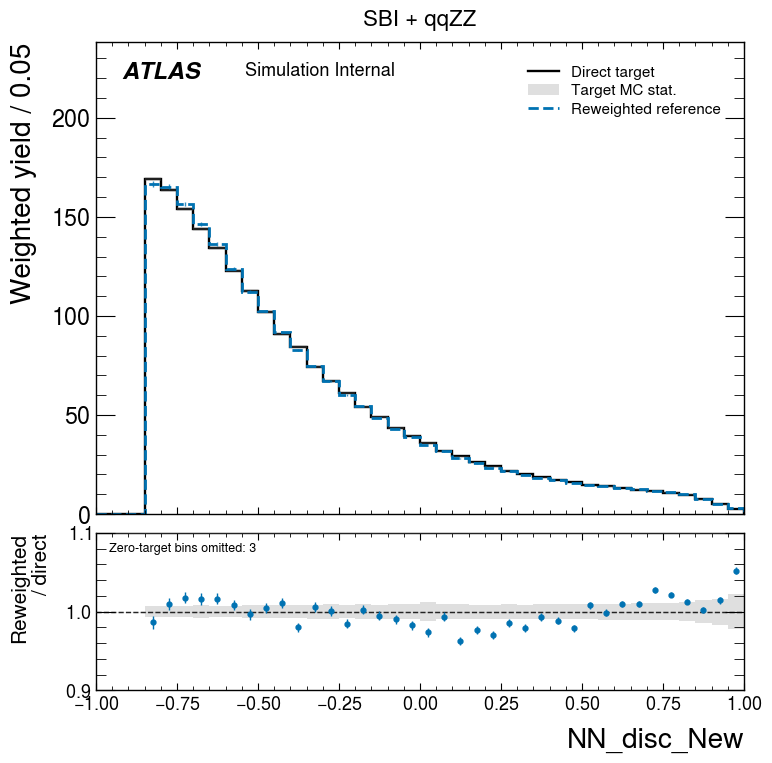

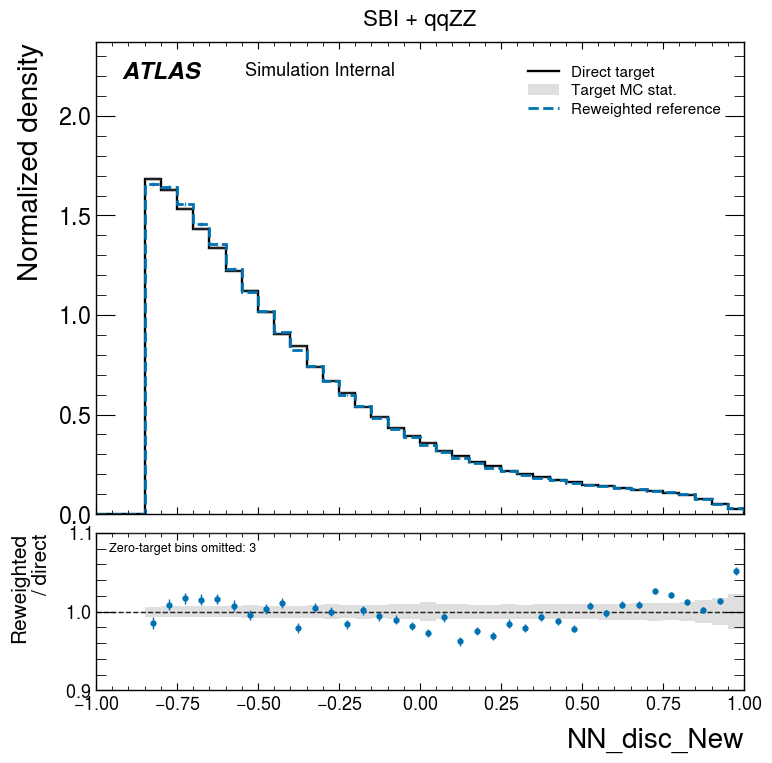

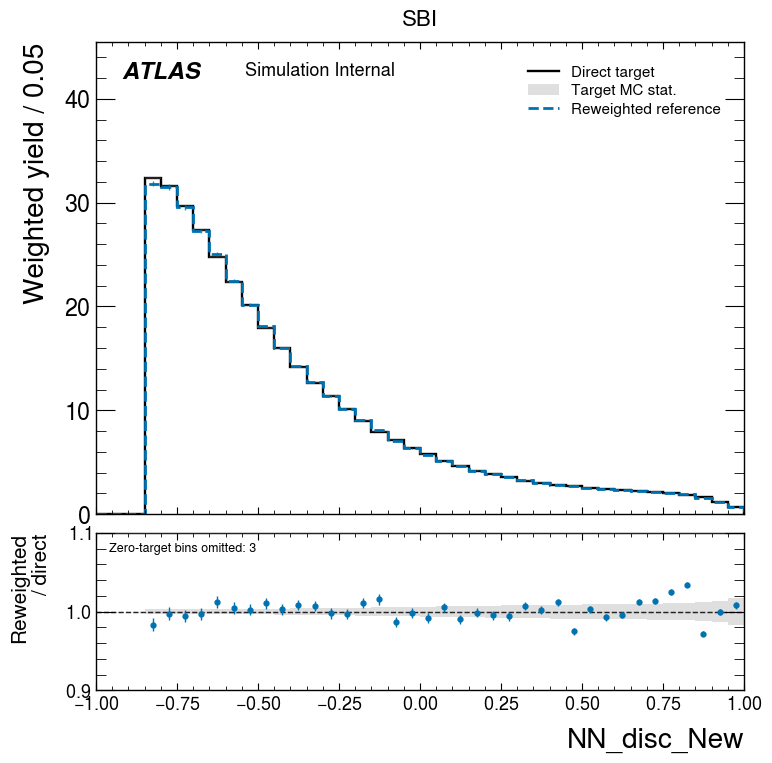

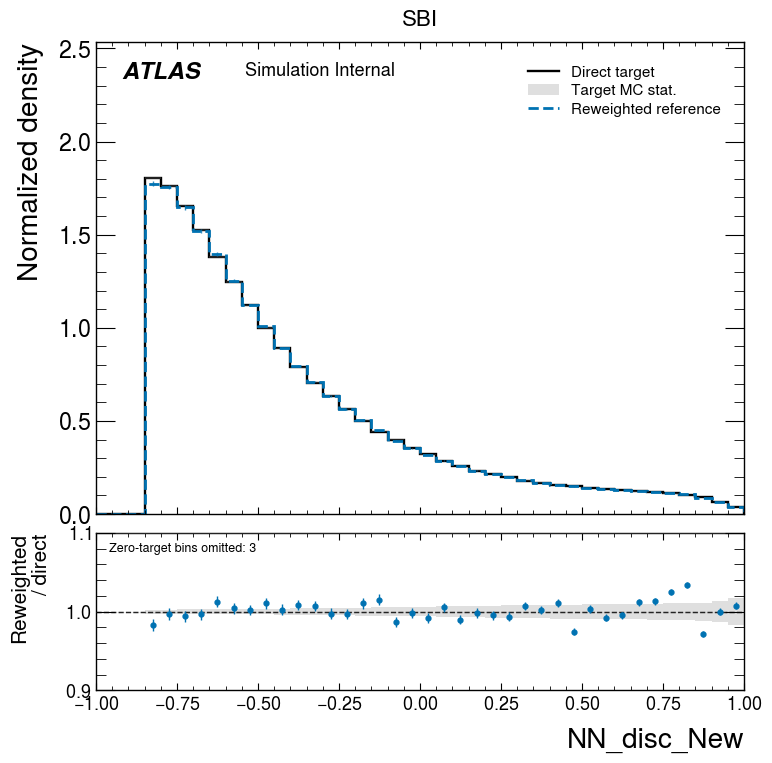

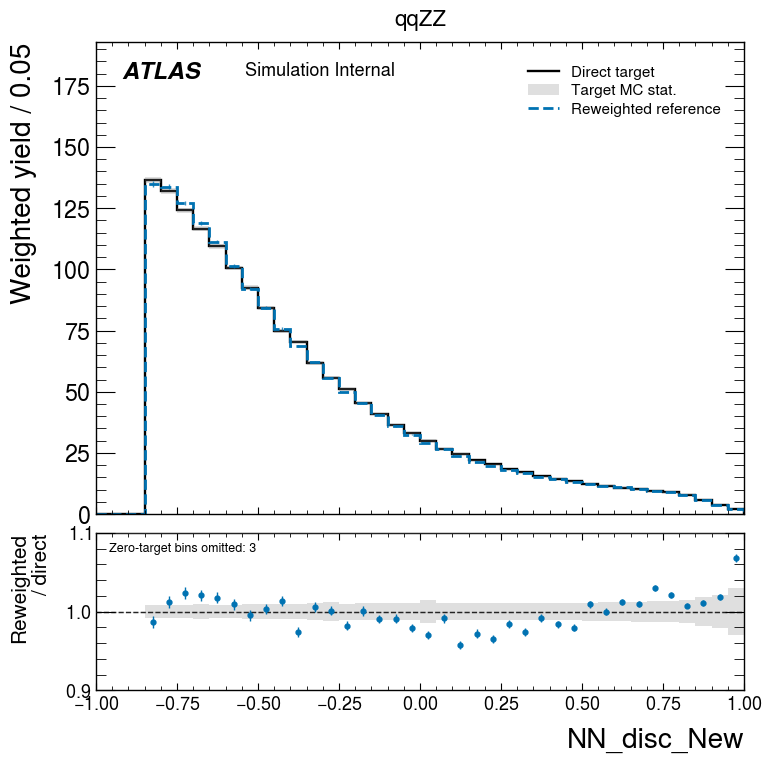

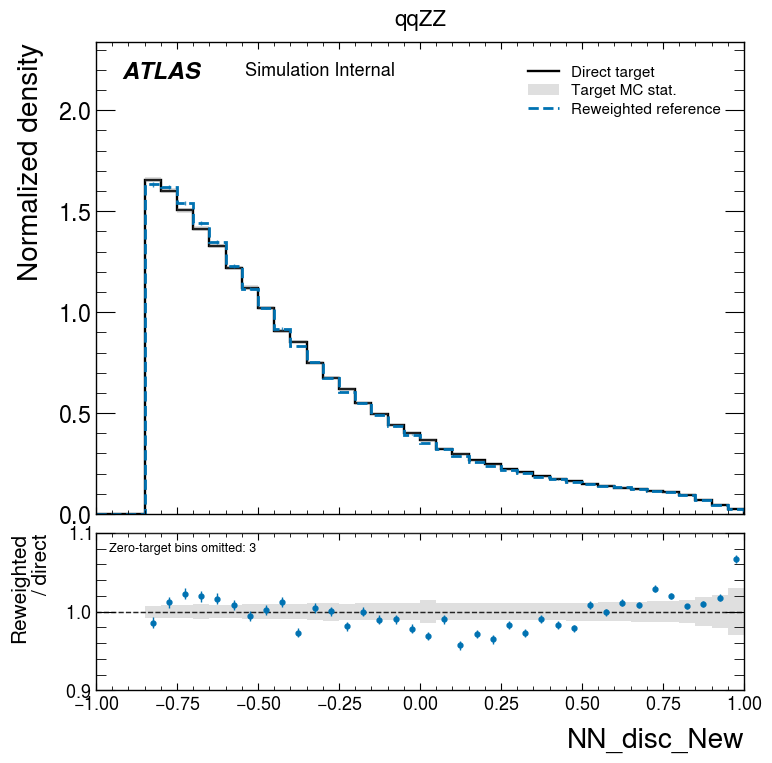

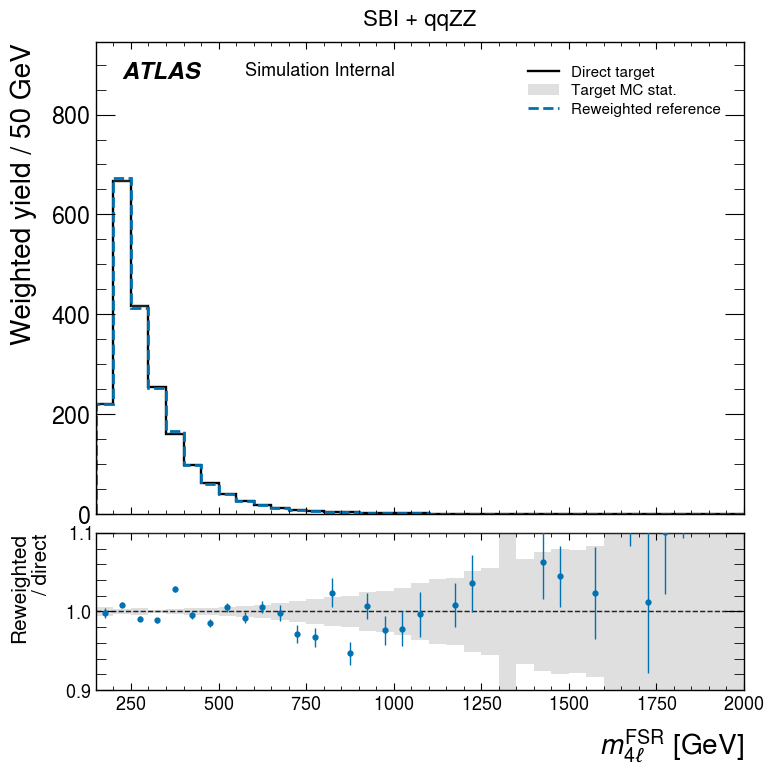

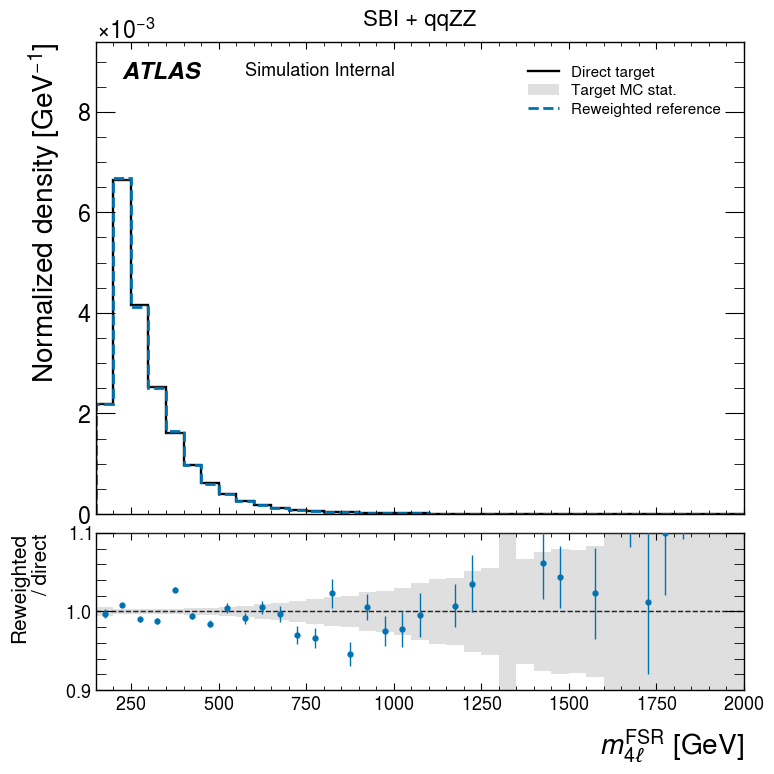

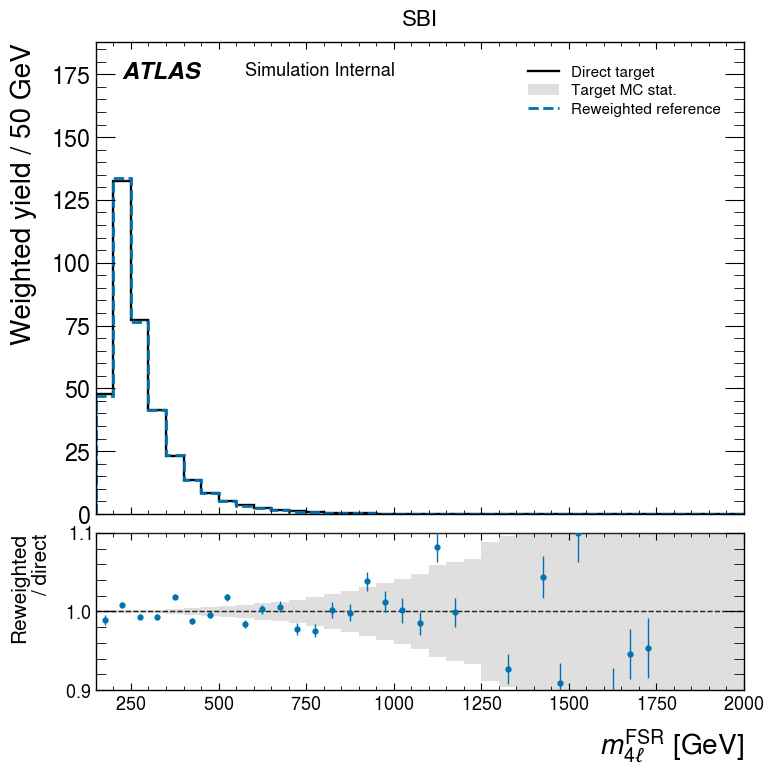

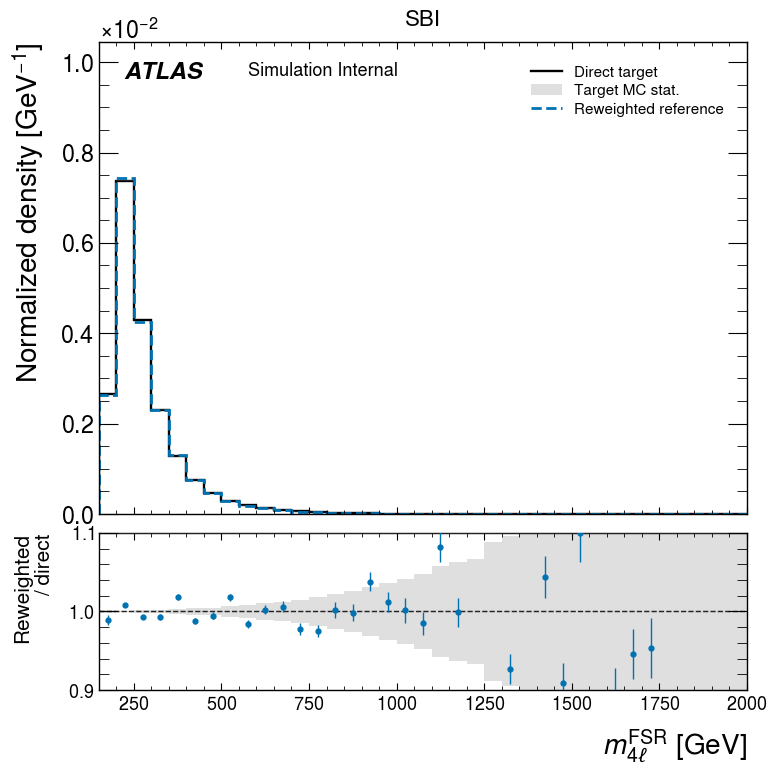

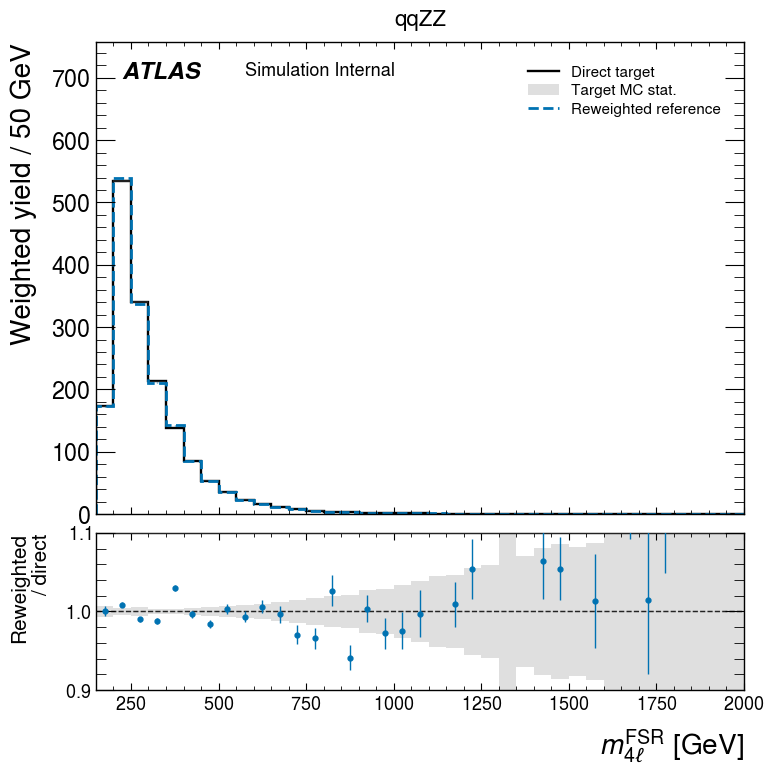

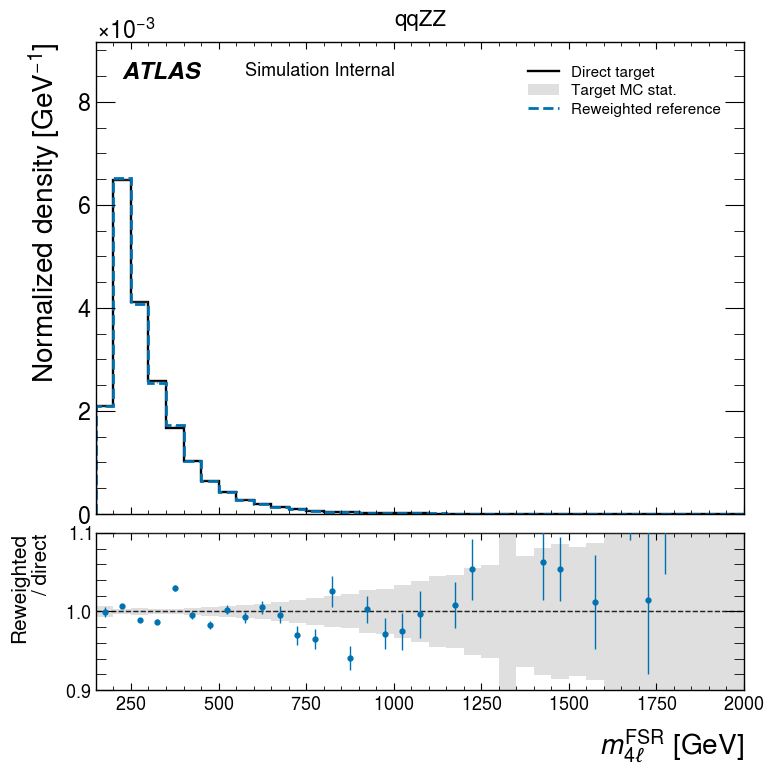

Figures saved to: /content/drive/MyDrive/Colab Notebooks/HZZ_OffShell/plots/02_reweighting_tests


In [6]:
range_closure = []
for variable, bins, xlabel, yield_label, density_label in variables:
    x_ref = data[variable][reference]
    for tag, name, direct_mask, rw_weights in comparisons:
        x_direct = data[variable][direct_mask]
        w_direct = weights[direct_mask]

        h_rw = np.histogram(x_ref, bins=bins, weights=rw_weights)[0]
        h_direct = np.histogram(x_direct, bins=bins, weights=w_direct)[0]
        v_rw = np.histogram(x_ref, bins=bins, weights=rw_weights**2)[0]
        v_direct = np.histogram(x_direct, bins=bins, weights=w_direct**2)[0]

        # Record all three regions, without folding flows into the edge bins.
        for region, ref_region, direct_region in [
            ("Below range", x_ref < bins[0], x_direct < bins[0]),
            ("In range", (x_ref >= bins[0]) & (x_ref <= bins[-1]),
             (x_direct >= bins[0]) & (x_direct <= bins[-1])),
            ("Above range", x_ref > bins[-1], x_direct > bins[-1]),
        ]:
            rw_yield = rw_weights[ref_region].sum()
            direct_yield = w_direct[direct_region].sum()
            range_closure.append({
                "variable": variable, "sample": name, "region": region,
                "direct_yield": direct_yield, "reweighted_yield": rw_yield,
                "reweighted/direct": rw_yield / direct_yield if direct_yield != 0 else np.nan,
            })

        for mode in ("yields", "normalized"):
            rw_plot, direct_plot = h_rw, h_direct
            rw_variance, direct_variance = v_rw, v_direct
            ylabel = yield_label
            if mode == "normalized":
                if h_rw.sum() == 0 or h_direct.sum() == 0:
                    print(f"Skipping {variable}, {name}: zero in-range signed yield")
                    continue
                rw_plot, rw_variance = normalize_histogram(h_rw, v_rw, bins)
                direct_plot, direct_variance = normalize_histogram(h_direct, v_direct, bins)
                ylabel = density_label

            fig, axes = plot_reweighting_comparison(
                rw_plot, direct_plot, rw_variance, direct_variance, bins,
                xlabel=xlabel, ylabel=ylabel, title=name, ratio_ylim=RATIO_YLIM,
            )
            for extension in ("png", "pdf"):
                fig.savefig(PLOT_DIR / f"{variable}_{tag}_{mode}.{extension}",
                            dpi=180, bbox_inches="tight")
            plt.show()
            plt.close(fig)

print(f"Figures saved to: {PLOT_DIR}")

## Yield closure inside and outside the plotting ranges

For each variable and sample, the three regions add back to the full selected-sample yield shown above. `NaN` in a ratio means the direct yield in that region is zero.

In [7]:
display(pd.DataFrame(range_closure).set_index(["variable", "sample", "region"]))

direct_yield  reweighted_yield  \
variable    sample     region                                        
NN_disc_New SBI + qqZZ Below range      0.000000          0.000000   
                       In range      2008.875271       2010.416457   
                       Above range      1.728552          1.712592   
            SBI        Below range      0.000000          0.000000   
                       In range       358.809081        358.888997   
                       Above range      0.476871          0.473777   
            qqZZ       Below range      0.000000          0.000000   
                       In range      1650.066189       1651.527460   
                       Above range      1.251681          1.238816   
m4l_fsr     SBI + qqZZ Below range      0.000000          0.000000   
                       In range      2010.603823       2012.129049   
                       Above range      0.000000          0.000000   
            SBI        Below range      0.000000          0.000000   
                       In range       359.285953        359.362774   
                       Above range      0.000000          0.000000   
            qqZZ       Below range      0.000000          0.000000   
                       In range      1651.317870       1652.766275   
                       Above range      0.000000          0.000000   

                                    reweighted/direct  
variable    sample     region                          
NN_disc_New SBI + qqZZ Below range                NaN  
                       In range              1.000767  
                       Above range           0.990767  
            SBI        Below range                NaN  
                       In range              1.000223  
                       Above range           0.993510  
            qqZZ       Below range                NaN  
                       In range              1.000886  
                       Above range           0.989722  
m4l_fsr     SBI + qqZZ Below range                NaN  
                       In range              1.000759  
                       Above range                NaN  
            SBI        Below range                NaN  
                       In range              1.000214  
                       Above range                NaN  
            qqZZ       Below range                NaN  
                       In range              1.000877  
                       Above range                NaN